# Aurora mPING precipitation-type verification + uncertainty analysis
End-to-end Aurora-only workflow: mPING QC, Day 1–7 matching, spatial collocation, ML vs Bourgouin verification, and reviewer-focused epistemic-uncertainty analysis.

**Key uncertainty hypothesis:** declining mixed-phase epistemic uncertainty at longer leads need not indicate improved skill; it may reflect a shift toward overwhelmingly rain/snow EDNN diagnoses and fewer mixed-phase regimes.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

MPING_PATH="/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"
BASE=Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
AURORA_DIR=BASE/"au_ptype"; OUT=BASE/"verification"; FIG=OUT/"figures_aurora"
OUT.mkdir(parents=True,exist_ok=True); FIG.mkdir(parents=True,exist_ok=True)

START=pd.Timestamp("2021-12-01"); END=pd.Timestamp("2022-04-01")
LAT_MIN,LAT_MAX=24.,50.; LON_MIN,LON_MAX=-125.,-66.
CONSENSUS=70.; MAX_DIST=30.

PTYPE_COLS={"sn_percent":"Snow","ra_percent":"Rain","pl_percent":"Ice Pellet","fzra_percent":"Freezing Rain"}
CLASS_NAMES={0:"Rain",1:"Snow",2:"Ice Pellet",3:"Freezing Rain"}
CLASS_CODES={v:k for k,v in CLASS_NAMES.items()}
CLASS_ORDER=["Rain","Snow","Ice Pellet","Freezing Rain"]; MIXED=["Ice Pellet","Freezing Rain"]
EPI={"Rain":"ML_rain_epi","Snow":"ML_snow_epi","Ice Pellet":"ML_icep_epi","Freezing Rain":"ML_frzr_epi"}
VARS=["ML_ptype","ML_rain","ML_snow","ML_icep","ML_frzr","ML_u",
      "ML_rain_ale","ML_snow_ale","ML_icep_ale","ML_frzr_ale",
      "ML_rain_epi","ML_snow_epi","ML_icep_epi","ML_frzr_epi","BOURG_ptype"]


## 1. Prepare mPING


In [2]:
def prepare_mping(path):
    cols=["datetime","lat","lon","report_count","sn_percent","ra_percent","pl_percent","fzra_percent"]
    d=pd.read_parquet(path,columns=cols); d["datetime"]=pd.to_datetime(d["datetime"])
    d=d[(d.datetime>=START)&(d.datetime<END)&d.datetime.dt.hour.isin([0,6,12,18])].copy()
    d=d[d.lat.between(LAT_MIN,LAT_MAX)&d.lon.between(LON_MIN,LON_MAX)].copy()
    pc=list(PTYPE_COLS); d["obs_class"]=d[pc].idxmax(axis=1).map(PTYPE_COLS); d["obs_consensus"]=d[pc].max(axis=1)
    if d.obs_consensus.max()<=1: d["obs_consensus"]*=100
    d=d[d.obs_consensus>=CONSENSUS].reset_index(drop=True); d["obs_id"]=np.arange(len(d))
    return d[["obs_id","datetime","lat","lon","report_count","obs_class","obs_consensus"]]

obs=prepare_mping(MPING_PATH)
print("N =",len(obs)); print(obs.obs_class.value_counts().reindex(CLASS_ORDER)); print(obs.datetime.dt.hour.value_counts().sort_index())


N = 29834
obs_class
Rain             11902
Snow             15894
Ice Pellet        1220
Freezing Rain      818
Name: count, dtype: int64
datetime
0      7682
6      5486
12     5440
18    11226
Name: count, dtype: int64


## 2. Build identical Day 1–7 valid-time matches


In [3]:
def expand_days(obs):
    z=[]
    for day in range(1,8):
        x=obs.copy(); h=x.datetime.dt.hour; x["forecast_day"]=day
        x["lead_hour"]=np.where(h==0,24*day,h+24*(day-1)).astype(int)
        x["init_time"]=x.datetime-pd.to_timedelta(x.lead_hour,unit="h"); z.append(x)
    return pd.concat(z,ignore_index=True)
matches=expand_days(obs)
assert matches.groupby("obs_id").size().eq(7).all() and not (matches.lead_hour==0).any()
print(matches.groupby("forecast_day").lead_hour.apply(lambda x:sorted(x.unique())))


forecast_day
1         [6, 12, 18, 24]
2        [30, 36, 42, 48]
3        [54, 60, 66, 72]
4        [78, 84, 90, 96]
5    [102, 108, 114, 120]
6    [126, 132, 138, 144]
7    [150, 156, 162, 168]
Name: lead_hour, dtype: object


## 3. Aurora nearest-grid collocation and spatial-distance QC


In [4]:
class Collocator:
    def path(self,t,l):
        s=pd.Timestamp(t).strftime("%Y-%m-%dT00Z")
        return AURORA_DIR/s/f"aurora_{s}_{int(l):03d}.nc"
    @staticmethod
    def hav(lat1,lon1,lat2,lon2):
        R=6371.; lat1,lon1,lat2,lon2=map(np.radians,[lat1,lon1,lat2,lon2])
        a=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
        return 2*R*np.arcsin(np.sqrt(a))
    def run(self,m):
        out=[]; groups=m.groupby(["init_time","lead_hour"]); n=len(groups)
        for i,((t,l),g) in enumerate(groups,1):
            p=self.path(t,l)
            if not p.exists(): print("[MISSING]",p); continue
            if i==1 or i%100==0 or i==n: print(f"{i}/{n}: {t} +{l:03d} h, N={len(g)}")
            with xr.open_dataset(p,decode_timedelta=False) as ds:
                q=ds.sel(latitude=xr.DataArray(g.lat.values,dims="obs"),
                         longitude=xr.DataArray(g.lon.values,dims="obs"),method="nearest")
                r=g.reset_index(drop=True).copy()
                r["grid_lat"]=np.asarray(q.latitude); r["grid_lon"]=np.asarray(q.longitude)
                r["grid_distance_km"]=self.hav(r.lat.values,r.lon.values,r.grid_lat.values,r.grid_lon.values)
                r["spatial_match_valid"]=r.grid_distance_km<=MAX_DIST
                for v in VARS:
                    if v in q: r[v]=np.asarray(q[v]).squeeze()
                out.append(r)
        return pd.concat(out,ignore_index=True)

aurora=Collocator().run(matches)
print("Rows:",len(aurora))
print(aurora.grid_distance_km.describe(percentiles=[.5,.9,.95,.99]))
print(">30 km:",(~aurora.spatial_match_valid).sum()," ML -1:",(aurora.ML_ptype==-1).sum())
aurora.to_parquet(OUT/"aurora_mping_collocations.parquet",index=False)


1/3325: 2021-11-24 00:00:00 +168 h, N=8


/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


100/3325: 2021-12-01 00:00:00 +072 h, N=2
200/3325: 2021-12-05 00:00:00 +024 h, N=62
300/3325: 2021-12-08 00:00:00 +120 h, N=18
400/3325: 2021-12-12 00:00:00 +048 h, N=24
500/3325: 2021-12-15 00:00:00 +144 h, N=6
600/3325: 2021-12-19 00:00:00 +072 h, N=34
700/3325: 2021-12-22 00:00:00 +168 h, N=102
800/3325: 2021-12-26 00:00:00 +096 h, N=72
900/3325: 2021-12-30 00:00:00 +024 h, N=106
1000/3325: 2022-01-02 00:00:00 +120 h, N=102
1100/3325: 2022-01-06 00:00:00 +048 h, N=24
1200/3325: 2022-01-09 00:00:00 +168 h, N=74
1300/3325: 2022-01-13 00:00:00 +114 h, N=122
1400/3325: 2022-01-17 00:00:00 +042 h, N=46
1500/3325: 2022-01-20 00:00:00 +138 h, N=44
1600/3325: 2022-01-24 00:00:00 +066 h, N=22
1700/3325: 2022-01-28 00:00:00 +030 h, N=186
1800/3325: 2022-02-01 00:00:00 +006 h, N=8
1900/3325: 2022-02-04 00:00:00 +132 h, N=10
2000/3325: 2022-02-08 00:00:00 +072 h, N=52
2100/3325: 2022-02-12 00:00:00 +018 h, N=84
2200/3325: 2022-02-15 00:00:00 +138 h, N=12
2300/3325: 2022-02-19 00:00:00 +066 h, 

## 4. Common-valid ML/Bourgouin verification sample


In [5]:
v=aurora[aurora.spatial_match_valid & aurora.obs_class.isin(CLASS_ORDER) &
         aurora.ML_ptype.isin(CLASS_NAMES) & aurora.BOURG_ptype.isin(CLASS_NAMES)].copy()
v["obs_code"]=v.obs_class.map(CLASS_CODES).astype(int); v["ML_ptype"]=v.ML_ptype.astype(int); v["BOURG_ptype"]=v.BOURG_ptype.astype(int)
print("Common rows:",len(v)); print(v.groupby("forecast_day").size())


Common rows: 208690
forecast_day
1    29814
2    29806
3    29814
4    29792
5    29814
6    29828
7    29822
dtype: int64


## 5. Ptype skill: POD, FAR, CSI, F1 and frequency bias


In [6]:
def div(a,b): return np.nan if b==0 else a/b
def metrics(o,p,c):
    o=np.asarray(o)==c; p=np.asarray(p)==c
    tp=np.sum(o&p); fn=np.sum(o&~p); fp=np.sum(~o&p); tn=np.sum(~o&~p)
    return dict(N=len(o),Observed=int(tp+fn),Forecast=int(tp+fp),TP=int(tp),FN=int(fn),FP=int(fp),TN=int(tn),
                POD=div(tp,tp+fn),FAR=div(fp,tp+fp),CSI=div(tp,tp+fn+fp),F1=div(2*tp,2*tp+fp+fn),Bias=div(tp+fp,tp+fn))
def table(d,col,method,day="All"):
    x=d if day=="All" else d[d.forecast_day==day]; rows=[]
    for c,n in CLASS_NAMES.items():
        r=metrics(x.obs_code,x[col],c); r.update(Method=method,Forecast_Day=day,Class=n); rows.append(r)
    return pd.DataFrame(rows)
overall=pd.concat([table(v,"ML_ptype","ML"),table(v,"BOURG_ptype","Bourgouin")],ignore_index=True)
daily=pd.concat([table(v,c,m,d) for d in range(1,8) for c,m in [("ML_ptype","ML"),("BOURG_ptype","Bourgouin")]],ignore_index=True)
display(overall[["Method","Class","POD","FAR","CSI","F1","Bias"]].round(3))
daily.to_csv(OUT/"aurora_skill_by_day.csv",index=False)


,Method,Class,POD,FAR,CSI,F1,Bias
0,ML,Rain,0.876,0.162,0.749,0.857,1.045
1,ML,Snow,0.887,0.123,0.789,0.882,1.012
2,ML,Ice Pellet,0.238,0.498,0.192,0.323,0.473
3,ML,Freezing Rain,0.320,0.644,0.203,0.337,0.899
4,Bourgouin,Rain,0.893,0.226,0.708,0.829,1.154
5,Bourgouin,Snow,0.801,0.094,0.740,0.850,0.884
6,Bourgouin,Ice Pellet,0.251,0.509,0.199,0.332,0.512
7,Bourgouin,Freezing Rain,0.399,0.770,0.171,0.292,1.733


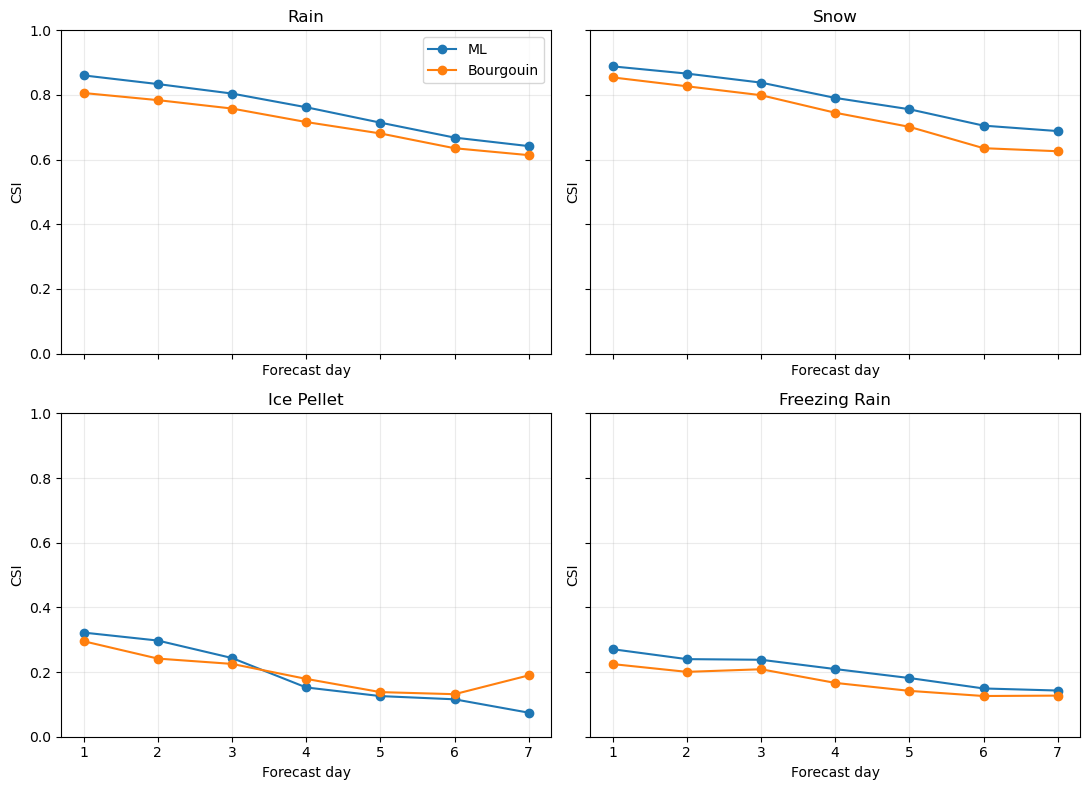

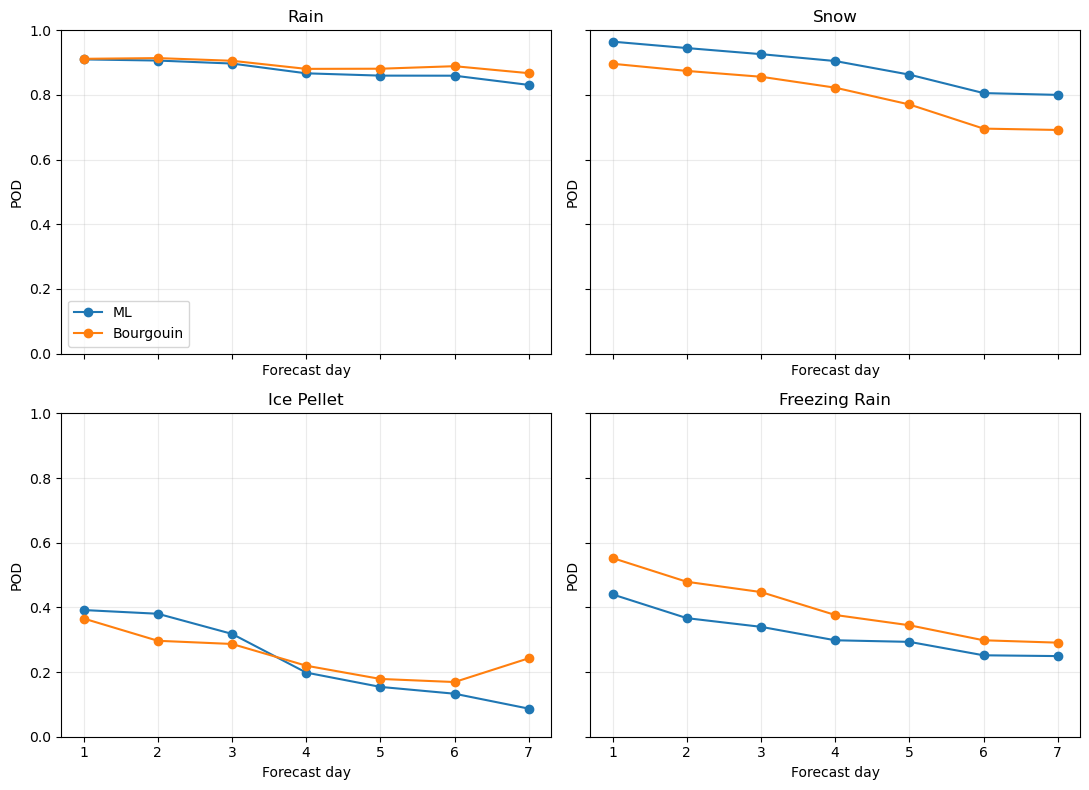

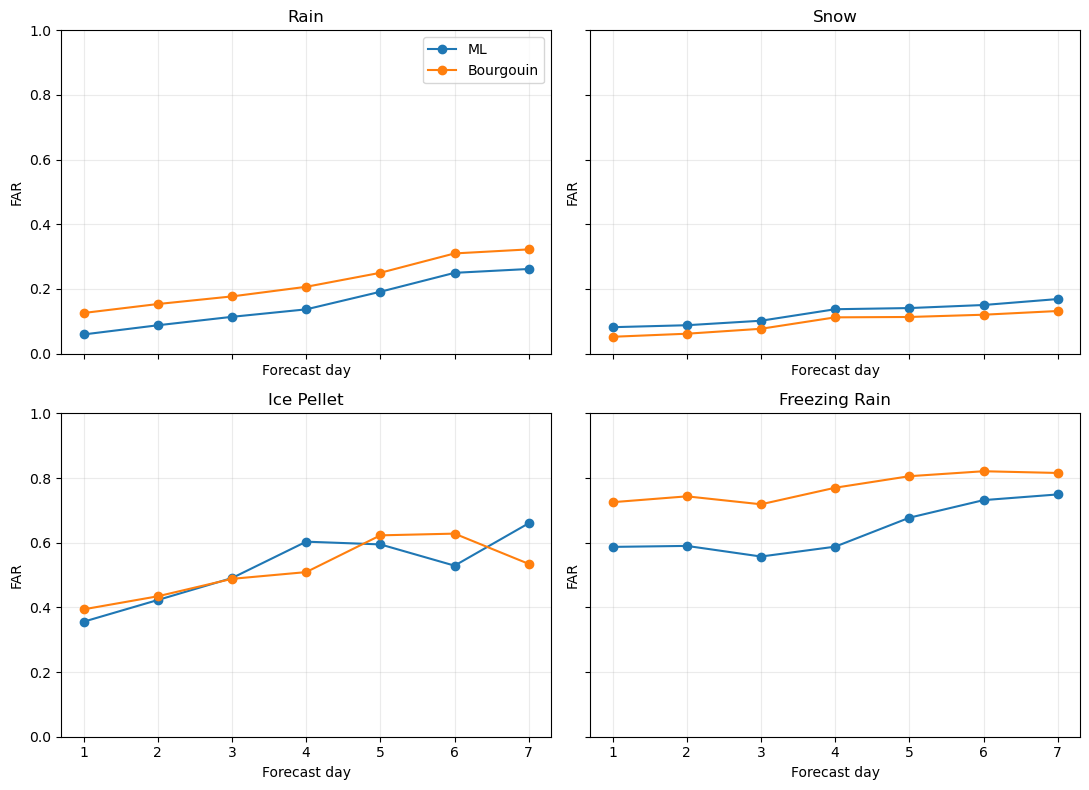

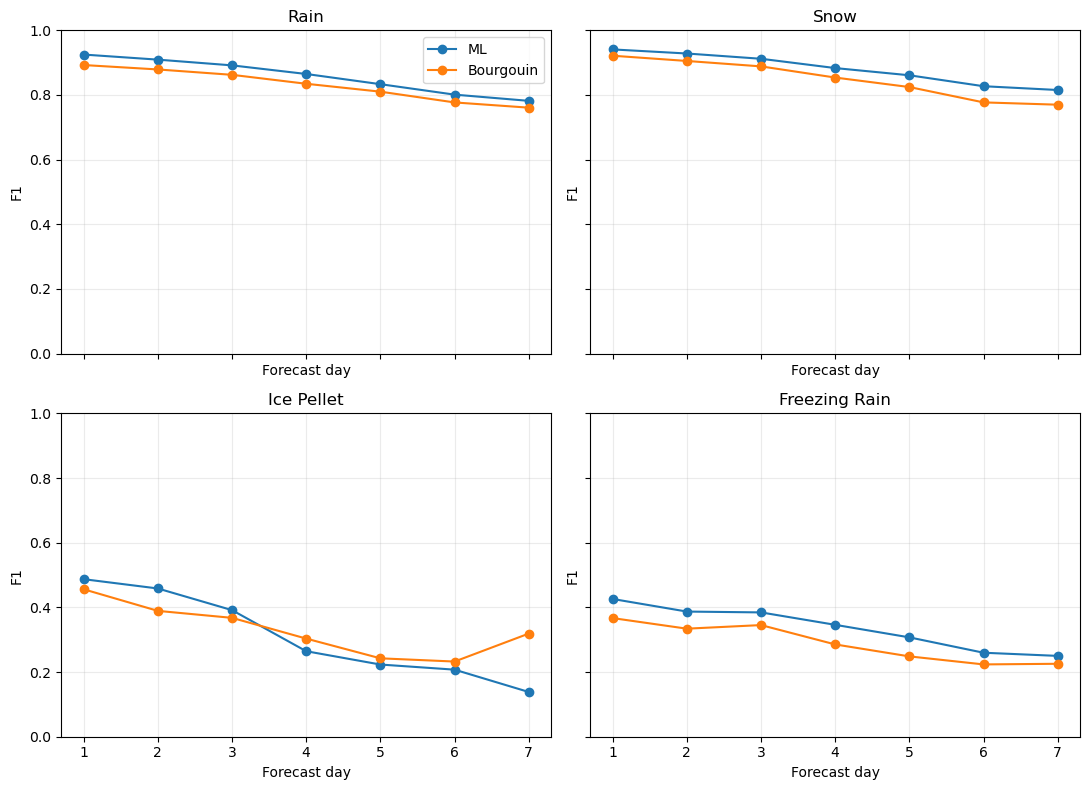

In [7]:
def skill_plot(metric):
    fig,axs=plt.subplots(2,2,figsize=(11,8),sharex=True,sharey=True)
    for ax,ptype in zip(axs.ravel(),CLASS_ORDER):
        for method in ["ML","Bourgouin"]:
            x=daily[(daily.Class==ptype)&(daily.Method==method)]
            ax.plot(x.Forecast_Day,x[metric],marker="o",label=method)
        ax.set_title(ptype); ax.set_xticks(range(1,8)); ax.set_ylim(0,1); ax.grid(alpha=.25); ax.set_xlabel("Forecast day"); ax.set_ylabel(metric)
    axs.ravel()[0].legend(); plt.tight_layout(); plt.show()
for metric in ["CSI","POD","FAR","F1"]: skill_plot(metric)


# Part II — Epistemic uncertainty with lead time


We use three complementary uncertainty definitions:
1. **Unconditional:** each class-specific epistemic field across all samples.
2. **Predicted-class conditional:** uncertainty for class *c* only where EDNN predicts *c*.
3. **Observed-class conditional:** uncertainty for class *c* where mPING observes *c*.

The observed-class view is especially useful for testing whether true mixed-phase events are becoming confidently reassigned to rain/snow at longer leads.


In [8]:
def unc_stats(mode="all"):
    rows=[]
    for day in range(1,8):
        d=v[v.forecast_day==day]
        for c,name in CLASS_NAMES.items():
            x=d[EPI[name]] if mode=="all" else d.loc[d.ML_ptype==c,EPI[name]] if mode=="predicted" else d.loc[d.obs_class==name,EPI[name]]
            x=x.dropna()
            rows.append(dict(forecast_day=day,Class=name,mode=mode,n=len(x),mean=x.mean(),median=x.median(),q25=x.quantile(.25),q75=x.quantile(.75)))
    return pd.DataFrame(rows)
epi_all=unc_stats("all"); epi_pred=unc_stats("predicted"); epi_obs=unc_stats("observed")
display(epi_pred.round(5)); display(epi_obs.round(5))


,forecast_day,Class,mode,n,mean,median,q25,q75
0,1,Rain,predicted,11514,0.00141,0.00001,0.00000,0.00015
1,1,Snow,predicted,16686,0.00171,0.00007,0.00002,0.00078
2,1,Ice Pellet,predicted,742,0.01520,0.01521,0.01357,0.01680
3,1,Freezing Rain,predicted,872,0.01380,0.01405,0.01100,0.01640
4,2,Rain,predicted,11824,0.00150,0.00001,0.00000,0.00018
5,2,Snow,predicted,16446,0.00171,0.00007,0.00002,0.00076
6,2,Ice Pellet,predicted,804,0.01600,0.01576,0.01380,0.01796
7,2,Freezing Rain,predicted,732,0.01475,0.01494,0.01168,0.01684
8,3,Rain,predicted,12044,0.00153,0.00001,0.00000,0.00020
9,3,Snow,predicted,16380,0.00183,0.00007,0.00002,0.00072


,forecast_day,Class,mode,n,mean,median,q25,q75
0,1,Rain,observed,11900,0.00134,0.00001,0.00000,0.00021
1,1,Snow,observed,15876,0.00147,0.00006,0.00002,0.00055
2,1,Ice Pellet,observed,1220,0.00922,0.01139,0.00169,0.01497
3,1,Freezing Rain,observed,818,0.00896,0.00937,0.00298,0.01386
4,2,Rain,observed,11898,0.00126,0.00001,0.00000,0.00018
5,2,Snow,observed,15870,0.00155,0.00006,0.00002,0.00058
6,2,Ice Pellet,observed,1220,0.00909,0.01080,0.00095,0.01504
7,2,Freezing Rain,observed,818,0.00847,0.00837,0.00168,0.01407
8,3,Rain,observed,11894,0.00121,0.00001,0.00000,0.00017
9,3,Snow,observed,15882,0.00170,0.00006,0.00002,0.00056


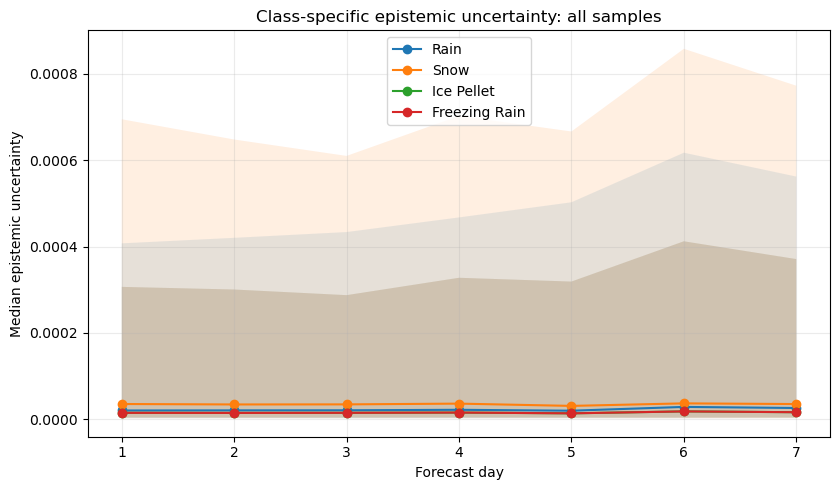

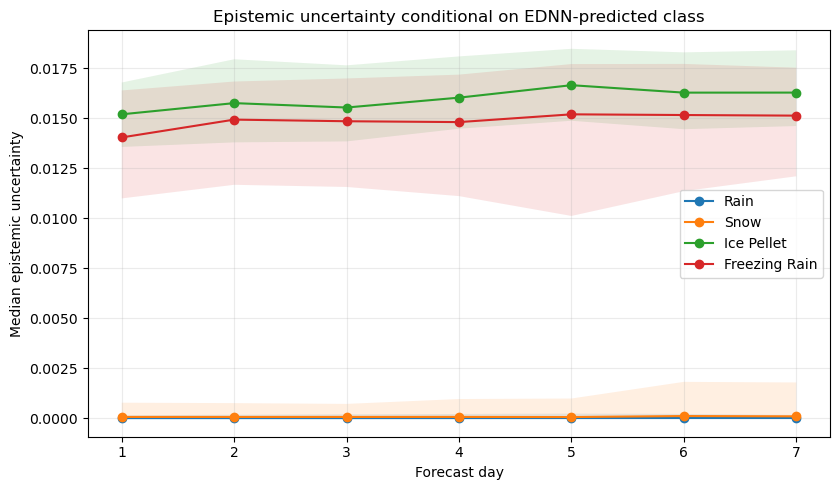

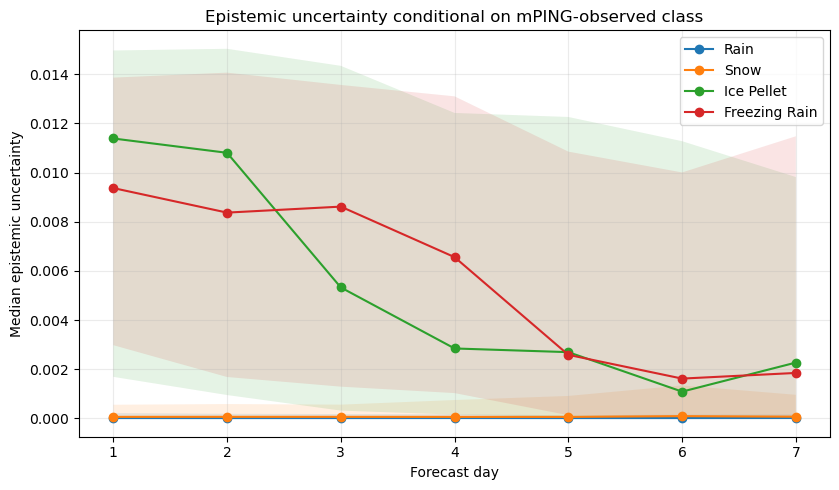

In [9]:
def unc_plot(s,title,classes=CLASS_ORDER):
    fig,ax=plt.subplots(figsize=(8.5,5))
    for p in classes:
        x=s[s.Class==p]
        ax.plot(x.forecast_day,x["median"],marker="o",label=p)
        ax.fill_between(x.forecast_day,x.q25,x.q75,alpha=.12)
    ax.set(title=title,xlabel="Forecast day",ylabel="Median epistemic uncertainty")
    ax.set_xticks(range(1,8)); ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

unc_plot(epi_all,"Class-specific epistemic uncertainty: all samples")
unc_plot(epi_pred,"Epistemic uncertainty conditional on EDNN-predicted class")
unc_plot(epi_obs,"Epistemic uncertainty conditional on mPING-observed class")


## 6. Does the forecast distribution shift toward rain/snow?


Class,Rain,Snow,Ice Pellet,Freezing Rain
forecast_day,,,,
1,38.62,55.97,2.49,2.92
2,39.67,55.18,2.70,2.46
3,40.40,54.94,2.56,2.11
4,40.12,55.84,2.05,1.99
5,42.43,53.52,1.56,2.50
6,45.74,50.54,1.15,2.57
7,44.92,51.30,1.05,2.73


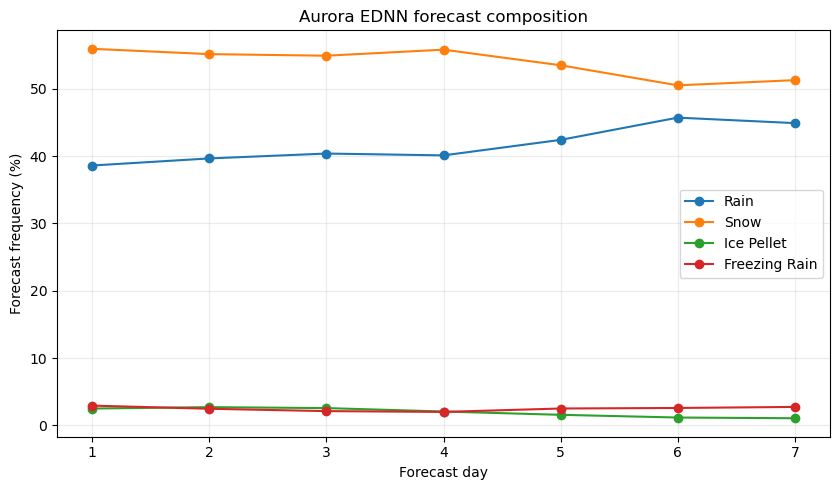

,mixed_pct,rain_snow_pct
forecast_day,,
1,5.414,94.586
2,5.153,94.847
3,4.662,95.338
4,4.035,95.965
5,4.052,95.948
6,3.728,96.272
7,3.776,96.224


In [10]:
freq=v.groupby(["forecast_day","ML_ptype"]).size().rename("n").reset_index()
freq["pct"]=freq.n/freq.groupby("forecast_day").n.transform("sum")*100; freq["Class"]=freq.ML_ptype.map(CLASS_NAMES)
F=freq.pivot(index="forecast_day",columns="Class",values="pct").reindex(columns=CLASS_ORDER).fillna(0)
display(F.round(2))
fig,ax=plt.subplots(figsize=(8.5,5))
for p in CLASS_ORDER: ax.plot(F.index,F[p],marker="o",label=p)
ax.set(title="Aurora EDNN forecast composition",xlabel="Forecast day",ylabel="Forecast frequency (%)")
ax.set_xticks(range(1,8)); ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

mixed=(v.assign(mixed=v.ML_ptype.isin([2,3])).groupby("forecast_day").mixed.mean()*100).rename("mixed_pct")
rain_snow=(v.assign(rs=v.ML_ptype.isin([0,1])).groupby("forecast_day").rs.mean()*100).rename("rain_snow_pct")
display(pd.concat([mixed,rain_snow],axis=1).round(3))


## 7. What does EDNN predict when mPING actually observes mixed phase?


Predicted,Rain,Snow,Ice Pellet,Freezing Rain
forecast_day,,,,
1,4.92,35.90,39.18,20.00
2,6.56,38.03,38.03,17.38
3,8.85,46.56,31.80,12.79
4,10.16,58.20,19.84,11.80
5,19.02,45.57,15.41,20.00
6,21.84,44.99,13.30,19.87
7,20.33,46.23,8.69,24.75


Predicted,Rain,Snow,Ice Pellet,Freezing Rain
forecast_day,,,,
1,23.23,16.63,16.14,44.01
2,26.41,17.85,19.07,36.67
3,24.94,24.94,16.14,33.99
4,22.49,33.25,14.43,29.83
5,32.52,32.03,6.11,29.34
6,34.96,33.50,6.36,25.18
7,35.21,33.99,5.87,24.94


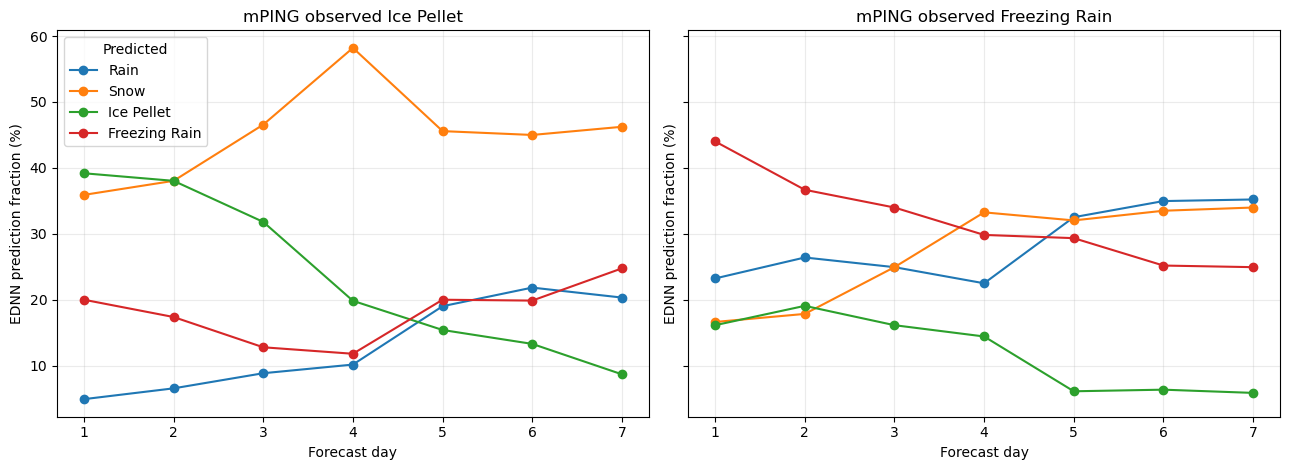

In [11]:
def true_class_predictions(name):
    x=v[v.obs_class==name]; z=x.groupby(["forecast_day","ML_ptype"]).size().rename("n").reset_index()
    z["pct"]=z.n/z.groupby("forecast_day").n.transform("sum")*100; z["Predicted"]=z.ML_ptype.map(CLASS_NAMES)
    return z.pivot(index="forecast_day",columns="Predicted",values="pct").reindex(columns=CLASS_ORDER).fillna(0)

IP=true_class_predictions("Ice Pellet"); FR=true_class_predictions("Freezing Rain")
display(IP.round(2)); display(FR.round(2))

fig,axs=plt.subplots(1,2,figsize=(13,4.8),sharey=True)
for ax,T,name in zip(axs,[IP,FR],["Ice Pellet","Freezing Rain"]):
    for p in CLASS_ORDER: ax.plot(T.index,T[p],marker="o",label=p)
    ax.set_title(f"mPING observed {name}"); ax.set_xlabel("Forecast day"); ax.set_ylabel("EDNN prediction fraction (%)"); ax.set_xticks(range(1,8)); ax.grid(alpha=.25)
axs[0].legend(title="Predicted"); plt.tight_layout(); plt.show()


## 8. Mixed-phase epistemic uncertainty versus CSI


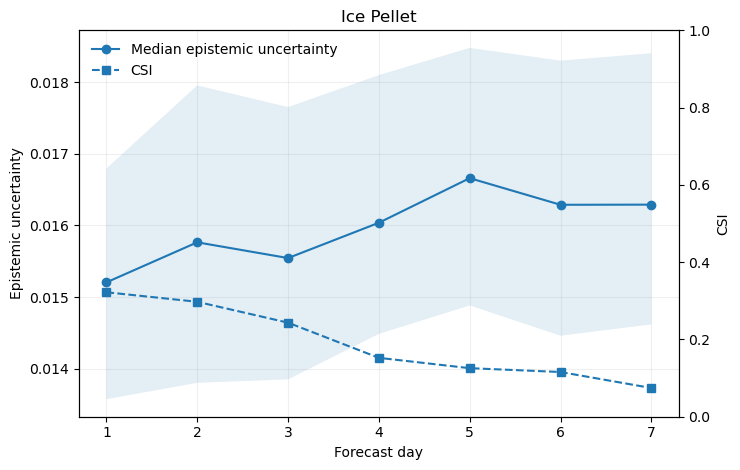

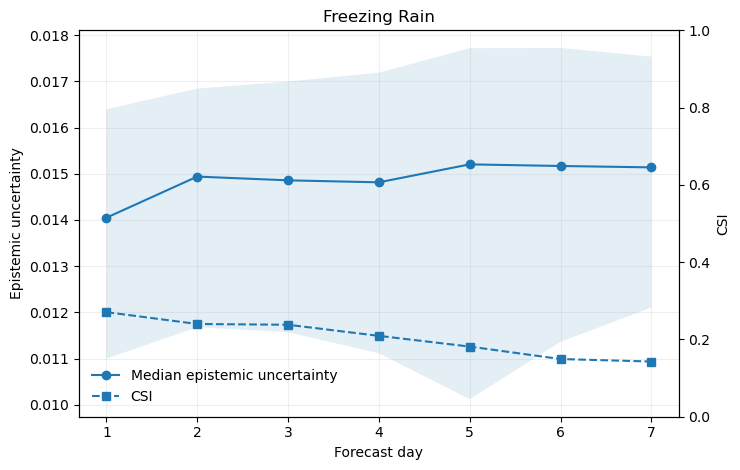

In [12]:
def uncertainty_vs_skill(ptype,stats=epi_pred):
    u=stats[stats.Class==ptype]; s=daily[(daily.Method=="ML")&(daily.Class==ptype)]
    fig,ax=plt.subplots(figsize=(7.5,4.8)); ax2=ax.twinx()
    a=ax.plot(u.forecast_day,u["median"],marker="o",label="Median epistemic uncertainty")
    ax.fill_between(u.forecast_day,u.q25,u.q75,alpha=.12)
    b=ax2.plot(s.Forecast_Day,s.CSI,marker="s",linestyle="--",label="CSI")
    ax.set(xlabel="Forecast day",ylabel="Epistemic uncertainty",title=ptype); ax.set_xticks(range(1,8)); ax.grid(alpha=.2)
    ax2.set_ylabel("CSI"); ax2.set_ylim(0,1); ax.legend(a+b,[q.get_label() for q in a+b],frameon=False)
    plt.tight_layout(); plt.show()
for p in MIXED: uncertainty_vs_skill(p)


## 9. Reviewer-oriented three-panel figure


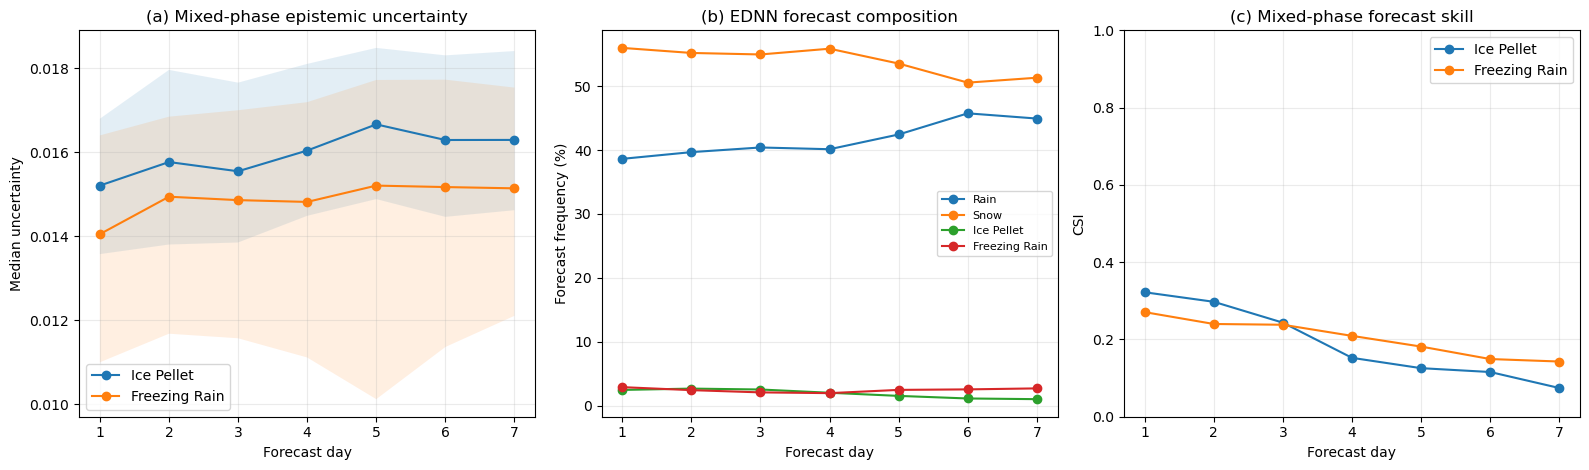

In [13]:
fig,axs=plt.subplots(1,3,figsize=(16,4.8))
for p in MIXED:
    x=epi_pred[epi_pred.Class==p]; axs[0].plot(x.forecast_day,x["median"],marker="o",label=p); axs[0].fill_between(x.forecast_day,x.q25,x.q75,alpha=.12)
axs[0].set(title="(a) Mixed-phase epistemic uncertainty",xlabel="Forecast day",ylabel="Median uncertainty"); axs[0].legend(); axs[0].grid(alpha=.25)

for p in CLASS_ORDER: axs[1].plot(F.index,F[p],marker="o",label=p)
axs[1].set(title="(b) EDNN forecast composition",xlabel="Forecast day",ylabel="Forecast frequency (%)"); axs[1].legend(fontsize=8); axs[1].grid(alpha=.25)

for p in MIXED:
    x=daily[(daily.Method=="ML")&(daily.Class==p)]; axs[2].plot(x.Forecast_Day,x.CSI,marker="o",label=p)
axs[2].set(title="(c) Mixed-phase forecast skill",xlabel="Forecast day",ylabel="CSI"); axs[2].set_ylim(0,1); axs[2].legend(); axs[2].grid(alpha=.25)

for ax in axs: ax.set_xticks(range(1,8))
plt.tight_layout(); plt.savefig(FIG/"aurora_uncertainty_regime_skill.png",dpi=300,bbox_inches="tight"); plt.show()


## 10. Alternative mechanism figure: condition uncertainty on mPING-observed mixed phase


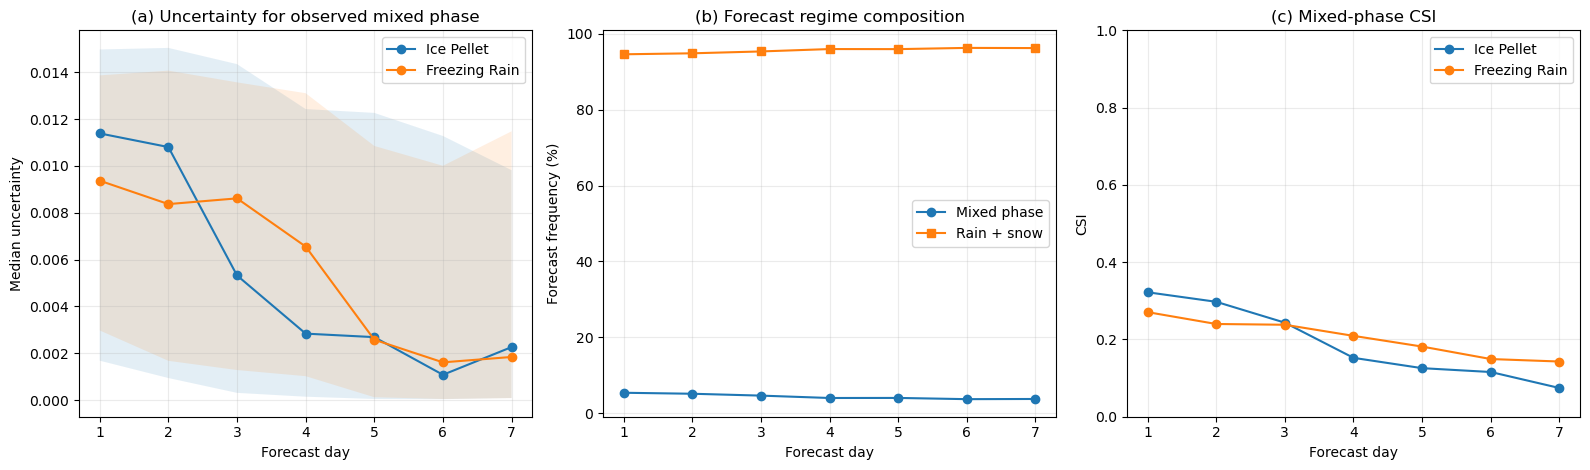

In [14]:
fig,axs=plt.subplots(1,3,figsize=(16,4.8))
for p in MIXED:
    x=epi_obs[epi_obs.Class==p]; axs[0].plot(x.forecast_day,x["median"],marker="o",label=p); axs[0].fill_between(x.forecast_day,x.q25,x.q75,alpha=.12)
axs[0].set(title="(a) Uncertainty for observed mixed phase",xlabel="Forecast day",ylabel="Median uncertainty"); axs[0].legend(); axs[0].grid(alpha=.25)
axs[1].plot(mixed.index,mixed.values,marker="o",label="Mixed phase"); axs[1].plot(rain_snow.index,rain_snow.values,marker="s",label="Rain + snow")
axs[1].set(title="(b) Forecast regime composition",xlabel="Forecast day",ylabel="Forecast frequency (%)"); axs[1].legend(); axs[1].grid(alpha=.25)
for p in MIXED:
    x=daily[(daily.Method=="ML")&(daily.Class==p)]; axs[2].plot(x.Forecast_Day,x.CSI,marker="o",label=p)
axs[2].set(title="(c) Mixed-phase CSI",xlabel="Forecast day",ylabel="CSI"); axs[2].set_ylim(0,1); axs[2].legend(); axs[2].grid(alpha=.25)
for ax in axs: ax.set_xticks(range(1,8))
plt.tight_layout(); plt.savefig(FIG/"aurora_uncertainty_mechanism.png",dpi=300,bbox_inches="tight"); plt.show()


## 11. Day-1 → Day-7 numerical summary and save tables


In [15]:
rows=[]
for p in MIXED:
    up=epi_pred[epi_pred.Class==p].set_index("forecast_day")["median"]
    uo=epi_obs[epi_obs.Class==p].set_index("forecast_day")["median"]
    sk=daily[(daily.Method=="ML")&(daily.Class==p)].set_index("Forecast_Day").CSI
    rows.append({"Class":p,"Pred epi D1":up.get(1,np.nan),"Pred epi D7":up.get(7,np.nan),"Pred epi change":up.get(7,np.nan)-up.get(1,np.nan),
                 "Obs epi D1":uo.get(1,np.nan),"Obs epi D7":uo.get(7,np.nan),"Obs epi change":uo.get(7,np.nan)-uo.get(1,np.nan),
                 "CSI D1":sk.get(1,np.nan),"CSI D7":sk.get(7,np.nan),"CSI change":sk.get(7,np.nan)-sk.get(1,np.nan)})
trend=pd.DataFrame(rows); display(trend.round(5))
display(pd.DataFrame({"Metric":["Mixed-phase forecast %","Rain + snow forecast %"],
                      "Day1":[mixed.loc[1],rain_snow.loc[1]],"Day7":[mixed.loc[7],rain_snow.loc[7]],
                      "Change":[mixed.loc[7]-mixed.loc[1],rain_snow.loc[7]-rain_snow.loc[1]]}).round(3))

epi_all.to_csv(OUT/"aurora_epi_all.csv",index=False); epi_pred.to_csv(OUT/"aurora_epi_predicted_class.csv",index=False)
epi_obs.to_csv(OUT/"aurora_epi_observed_class.csv",index=False); freq.to_csv(OUT/"aurora_class_frequency.csv",index=False)
IP.to_csv(OUT/"aurora_predictions_true_ice_pellet.csv"); FR.to_csv(OUT/"aurora_predictions_true_freezing_rain.csv")
trend.to_csv(OUT/"aurora_mixed_phase_trend_summary.csv",index=False)
print("Tables and figures saved under",OUT)


,Class,Pred epi D1,Pred epi D7,Pred epi change,Obs epi D1,Obs epi D7,Obs epi change,CSI D1,CSI D7,CSI change
0,Ice Pellet,0.01521,0.01629,0.00109,0.01139,0.00227,-0.00912,0.32210,0.07433,-0.24777
1,Freezing Rain,0.01405,0.01514,0.00109,0.00937,0.00185,-0.00752,0.27068,0.14286,-0.12782


,Metric,Day1,Day7,Change
0,Mixed-phase forecast %,5.414,3.776,-1.638
1,Rain + snow forecast %,94.586,96.224,1.638


Tables and figures saved under /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/verification


## Interpretation guardrail
A decline in epistemic uncertainty should **not** be interpreted by itself as improved forecast skill. The reviewer-facing interpretation is supported only if the diagnostics jointly show that mixed-phase uncertainty decreases while mixed-phase forecasts become less frequent / rain-snow forecasts become more dominant, without a corresponding improvement in mixed-phase CSI.
